# Proyek Analisis Data: Bike Sharing

- **Nama:** Tegar Dwi Nugraha
- **Email:** tegardwinugraha20@gmail.com
- **ID Dicoding:** tgardwn



**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

1. **Bagaimana perubahan rata-rata penyewaan sepeda harian menurut bulan dan musim selama periode 1 Januari 2011 hingga 31 Desember 2012?**
2. **Pada jam berapa rata-rata penyewaan sepeda tertinggi terjadi pada hari kerja dan bukan hari kerja selama periode 1 Januari 2011 hingga 31 Desember 2012?**


## Import Semua Packages/Library yang Digunakan

Library yang akan digunakan adalah `pandas`, `matplotlib`, dan `path`. `pandas` digunakan untuk membaca dan mengelompokkan data, `matplotlib` untuk membuat grafik, dan `Path` dipakai agar notebook bisa membaca file dari folder ZIP maupun Colab.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
plt.rcParams['figure.dpi'] = 110

## Data Wrangling
### Gathering Data

Kedua file dibaca secara terpisah. Alasan untuk tidak menggabungkan keduanya adalah karena hal tersebut dapat membuat penyewaan yang sama ikut terhitung dua kali.

In [ ]:
day_df = pd.read_csv( 'day.csv')
hour_df = pd.read_csv('hour.csv')

print('Ukuran day.csv :', day_df.shape)
print('Ukuran hour.csv:', hour_df.shape)

Ukuran day.csv : (731, 16)
Ukuran hour.csv: (17379, 17)


#### Melihat lima baris pertama

Kedua dataset diperiksa terlebih dahulu untuk melihat variabel-variabel yang ada.

In [ ]:
print('Data harian:')
display(day_df.head())

print('Data per jam:')
display(hour_df.head())

Data harian:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Data per jam:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


#### Memeriksa kolom

Kolom utama yang dipakai: `dteday` (tanggal), `season` (musim), `workingday` (hari kerja), `hr` (jam, hanya di `hour.csv`), `casual` (penyewaan pengguna kasual), `registered` (penyewaan pengguna terdaftar), dan `cnt` (total penyewaan).

In [ ]:
print('Nama kolom day.csv:')
print(day_df.columns.tolist())

print('\nNama kolom hour.csv:')
print(hour_df.columns.tolist())

kolom_day = {'dteday', 'cnt', 'casual', 'registered', 'season', 'workingday'}
kolom_hour = kolom_day | {'hr'}

if not kolom_day.issubset(day_df.columns):
    raise ValueError('Ada kolom penting yang tidak ditemukan di day.csv')
if not kolom_hour.issubset(hour_df.columns):
    raise ValueError('Ada kolom penting yang tidak ditemukan di hour.csv')

Nama kolom day.csv:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Nama kolom hour.csv:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


**Hasil Gathering:** `day.csv` berisi **731 baris dan 16 kolom**, sedangkan `hour.csv` berisi **17.379 baris dan 17 kolom**. Keduanya mencakup **1 Januari 2011–31 Desember 2012**. Dengan adanya catatan harian dan per jam, saya bisa melihat tren umum tanpa kehilangan informasi jam sibuk.

In [ ]:
print('Jumlah hari tercatat:', len(day_df))
print('Jumlah catatan per jam:', len(hour_df))
print('Rentang tanggal harian:', pd.to_datetime(day_df['dteday']).min().date(),
      'sampai', pd.to_datetime(day_df['dteday']).max().date())

Jumlah hari tercatat: 731
Jumlah catatan per jam: 17379
Rentang tanggal harian: 2011-01-01 sampai 2012-12-31


### Assessing Data

Pemeriksaan terhadap tipe data, nilai kosong, duplikasi, dan apakah jumlah penyewaan (`cnt`) sesuai dengan penjumlahan `casual + registered`. Ini dilakukan sebelum data digunakan untuk membuat grafik.

#### 1. Tipe data

Pemeriksaan terhadap tipe data pada seluruh dataset.


In [ ]:
print('day.csv')
day_df.info()

print('\nhour.csv')
hour_df.info()

day.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

hour.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378

#### 2. Nilai kosong

Pemeriksaan terhadap nilai yang kosong pada tiap kolom.

In [ ]:
print('Nilai kosong pada day.csv:')
print(day_df.isna().sum())

print('\nNilai kosong pada hour.csv:')
print(hour_df.isna().sum())

Nilai kosong pada day.csv:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Nilai kosong pada hour.csv:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


#### 3. Duplikasi

Pemeriksaan duplikasi pada seluruh baris `dteday` pada data harian dan pasangan `dteday`–`hr` pada data per jam.

In [ ]:
print('Baris identik day.csv:', day_df.duplicated().sum())
print('Tanggal ganda day.csv:', day_df.duplicated(subset='dteday').sum())

print('Baris identik hour.csv:', hour_df.duplicated().sum())
print('Tanggal-jam ganda hour.csv:',
      hour_df.duplicated(subset=['dteday', 'hr']).sum())

Baris identik day.csv: 0
Tanggal ganda day.csv: 0
Baris identik hour.csv: 0
Tanggal-jam ganda hour.csv: 0


#### 4. Memeriksa nilai jumlah penyewaan

Karena `cnt = casual + registered`, ketidaksesuaian pada rumus ini perlu dipastikan kembali.

In [ ]:
print('Baris tidak konsisten pada day.csv:',
      (day_df['casual'] + day_df['registered'] != day_df['cnt']).sum())
print('Baris tidak konsisten pada hour.csv:',
      (hour_df['casual'] + hour_df['registered'] != hour_df['cnt']).sum())
print('Jam di luar 0–23:', (~hour_df['hr'].between(0, 23)).sum())
print('Jumlah penyewaan negatif (harian):', (day_df['cnt'] < 0).sum())
print('Jumlah penyewaan negatif (per jam):', (hour_df['cnt'] < 0).sum())

print('\nStatistik jumlah penyewaan harian:')
display(day_df['cnt'].describe())

Baris tidak konsisten pada day.csv: 0
Baris tidak konsisten pada hour.csv: 0
Jam di luar 0–23: 0
Jumlah penyewaan negatif (harian): 0
Jumlah penyewaan negatif (per jam): 0

Statistik jumlah penyewaan harian:


,cnt
count,731.000000
mean,4504.348837
std,1937.211452
min,22.000000
25%,3152.000000
50%,4548.000000
75%,5956.000000
max,8714.000000


**Hasil Assessing:** Tidak ditemukan nilai kosong, baris duplikat, tanggal harian yang berulang, atau pasangan tanggal–jam yang berulang. Di kedua dataset, seluruh nilai `cnt` sama dengan `casual + registered`. Tidak ada jam di luar 0–23 dan tidak ada jumlah penyewaan negatif.

**Catatan penting:** Ada **165 slot jam** yang tidak muncul apabila dibandingkan dengan 731 hari × 24 jam. Jadi, tidak semua tanggal mempunyai 24 baris pada `hour.csv`. Saya **tidak mengisi jam yang tidak tercatat dengan nol** karena file tidak menjelaskan secara pasti alasan ketidakhadirannya. Grafik per jam karena itu memakai **rata-rata per baris jam yang tercatat**.

### Cleaning Data

Dataset tidak perlu ditangani karena tidak ada yang "bermasalah". Hanya saja, ada perubahan kolom tanggal menjadi `datetime` dan membuat label yang lebih mudah dibaca untuk bulan, musim, serta jenis hari.

In [ ]:
day_df = day_df.copy()
hour_df = hour_df.copy()

day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

day_df['tahun_bulan'] = day_df['dteday'].dt.strftime('%Y-%m')

nama_musim = {1: 'Semi', 2: 'Panas', 3: 'Gugur', 4: 'Dingin'}
day_df['musim'] = day_df['season'].map(nama_musim)

nama_hari = {0: 'Bukan hari kerja', 1: 'Hari kerja'}
hour_df['jenis_hari'] = hour_df['workingday'].map(nama_hari)

print('Tipe tanggal harian:', day_df['dteday'].dtype)
print('Tipe tanggal per jam:', hour_df['dteday'].dtype)
display(day_df[['dteday', 'tahun_bulan', 'musim']].head())

Tipe tanggal harian: datetime64[ns]
Tipe tanggal per jam: datetime64[ns]


,dteday,tahun_bulan,musim
0,2011-01-01,2011-01,Semi
1,2011-01-02,2011-01,Semi
2,2011-01-03,2011-01,Semi
3,2011-01-04,2011-01,Semi
4,2011-01-05,2011-01,Semi


**Hasil Cleaning:** Kedua kolom `dteday` sudah menjadi tanggal. Kolom tambahan `tahun_bulan`, `musim`, dan `jenis_hari` hanya dipakai untuk mempermudah pengelompokan serta pemberian label grafik. **Jumlah baris tetap sama**, yaitu 731 dan 17.379.

## Exploratory Data Analysis (EDA)

Pada tahap ini saya membandingkan **rata-rata penyewaan**, bukan total keseluruhan, karena jumlah hari di tiap bulan atau jumlah jam yang tercatat pada kelompok tertentu bisa berbeda. EDA masih bertujuan mengenali pola; interpretasinya belum berarti sebab-akibat.

### EDA 1 — Tren bulanan (`day.csv`)

Rata-rata `cnt` dihitung setiap bulan dalam urutan waktu. Alasan penggunaan rata-rata adalah melihat apakah ada tren dari penjualannya atau tidak. Bulan dari tahun 2011 dan 2012 ditampilkan terpisah agar perubahan antartahun terlihat.

In [ ]:
bulanan = day_df.groupby('tahun_bulan')['cnt'].mean().sort_index()
print('Rata-rata penyewaan per hari dalam setiap bulan:')
display(bulanan.round(1))

Rata-rata penyewaan per hari dalam setiap bulan:


,cnt
tahun_bulan,
2011-01,1231.9
2011-02,1722.0
2011-03,2066.0
2011-04,3162.3
2011-05,4381.3
2011-06,4783.7
2011-07,4559.4
2011-08,4409.4
2011-09,4247.3


### EDA 2 — Perbandingan musim (`day.csv`)

Kode `season` mengikuti keterangan dataset: 1 = Semi, 2 = Panas, 3 = Gugur, dan 4 = Dingin. Rata-rata penyewaan harian digunakan untuk membandingkan empat musim tersebut.

In [ ]:
urutan_musim = ['Semi', 'Panas', 'Gugur', 'Dingin']
musiman = day_df.groupby('musim')['cnt'].mean().reindex(urutan_musim)
display(musiman.round(1))

,cnt
musim,
Semi,2604.1
Panas,4992.3
Gugur,5644.3
Dingin,4728.2


### EDA 3 — Pola menurut jam (`hour.csv`)

Rata-rata `cnt` digunakan untuk masing-masing jam 00–23 dari seluruh baris jam yang tercatat.

In [ ]:
per_jam = hour_df.groupby('hr')['cnt'].mean().reindex(range(24))
display(per_jam.round(1))

,cnt
hr,
0,53.9
1,33.4
2,22.9
3,11.7
4,6.4
5,19.9
6,76.0
7,212.1
8,359.0


### EDA 4 — Hari kerja dan bukan hari kerja (`hour.csv`)

Nilai `workingday = 1` menunjukkan hari kerja. Nilai 0 adalah bukan hari kerja, termasuk akhir pekan dan hari libur. Pengelompokan ini membantu melihat apakah jam ramai terjadi pada waktu yang sama.

In [ ]:
jam_hari = hour_df.groupby(['hr', 'jenis_hari'])['cnt'].mean().unstack()
jam_hari = jam_hari.reindex(range(24))
display(jam_hari.round(1))

jenis_hari,Bukan hari kerja,Hari kerja
hr,,
0,90.8,36.8
1,69.5,16.6
2,53.2,8.7
3,25.8,4.9
4,8.3,5.4
5,8.7,24.9
6,18.7,102.5
7,43.4,290.6
8,105.7,477.0


**Hasil EDA:** Rata-rata penyewaan harian tertinggi pada **September 2012**, sekitar **7.285,8 penyewaan/hari**. Musim dengan rata-rata tertinggi adalah **gugur**, sekitar **5.644,3 penyewaan/hari** (gabungan 2011–2012).

Rata-rata penyewaan per jam secara keseluruhan paling tinggi pada **pukul 17.00**, sekitar **461,5 penyewaan per catatan jam**. Namun, setelah dipisahkan menurut jenis hari, jam puncaknya ternyata berbeda: **17.00 pada hari kerja** dan **13.00 pada bukan hari kerja**.

In [ ]:
print('Bulan paling ramai:', bulanan.idxmax(),
      f'(rata-rata {bulanan.max():,.1f} sewa/hari)')
print('Musim paling ramai:', musiman.idxmax(),
      f'(rata-rata {musiman.max():,.1f} sewa/hari)')
print('Jam paling ramai:', f'{int(per_jam.idxmax()):02d}.00',
      f'(rata-rata {per_jam.max():,.1f} sewa/jam pengamatan)')

Bulan paling ramai: 2012-09 (rata-rata 7,285.8 sewa/hari)
Musim paling ramai: Gugur (rata-rata 5,644.3 sewa/hari)
Jam paling ramai: 17.00 (rata-rata 461.5 sewa/jam pengamatan)


## Visualization & Explanatory Analysis

Saya memakai grafik garis untuk melihat perubahan dari waktu ke waktu dan grafik batang untuk membandingkan kategori. Sumbu Y dimulai dari nol pada grafik batang. Setiap grafik menyebutkan satuan supaya total penyewaan tidak tertukar dengan rata-rata.

### Pertanyaan 1 — Bagaimana perubahan rata-rata penyewaan sepeda harian menurut bulan dan musim selama periode 1 Januari 2011 hingga 31 Desember 2012?

**Grafik 1.** Rata-rata jumlah penyewaan per hari untuk tiap bulan dari Januari 2011 sampai Desember 2012. Grafik garis cocok untuk menunjukkan pergerakan waktu secara berurutan.

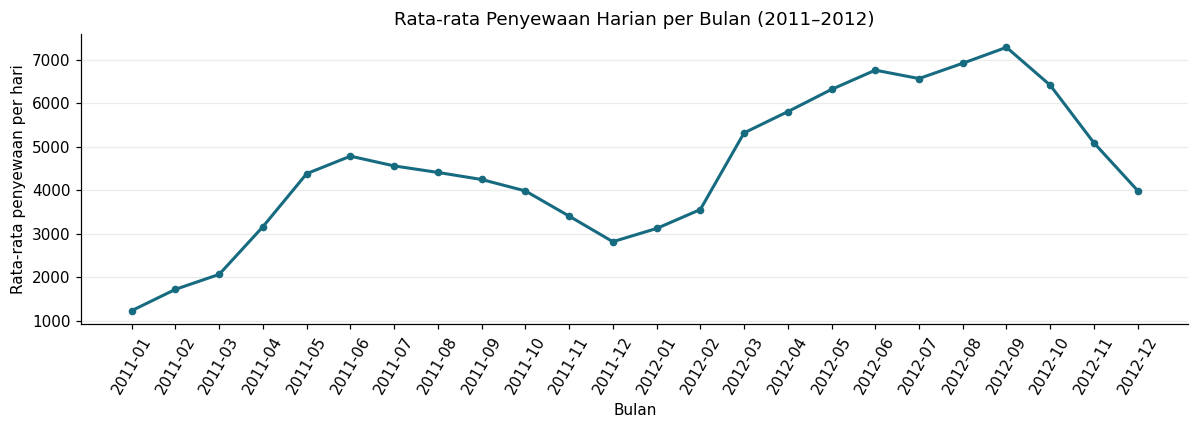

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(bulanan.index, bulanan.values, marker='o', markersize=4,
        linewidth=2, color='#176B80')
ax.set_title('Rata-rata Penyewaan Harian per Bulan (2011–2012)')
ax.set_xlabel('Bulan')
ax.set_ylabel('Rata-rata penyewaan per hari')
ax.tick_params(axis='x', rotation=60)
ax.grid(axis='y', alpha=0.25)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Grafik 2.** Rata-rata penyewaan harian menurut musim sepanjang dua tahun. Grafik batang dipakai karena musim merupakan kategori, bukan urutan waktu yang terus-menerus.

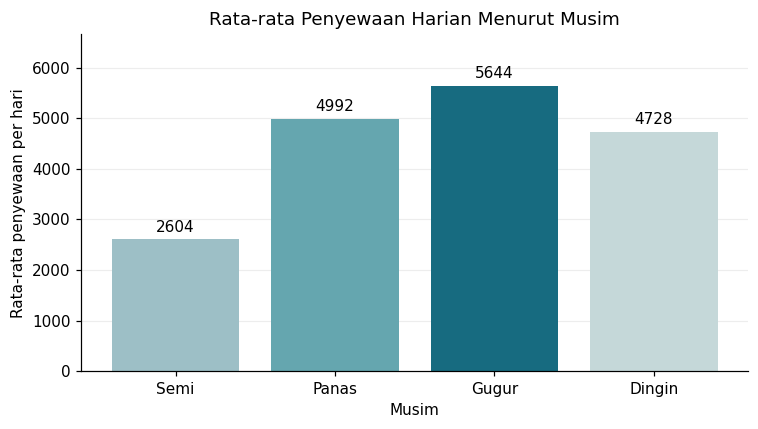

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(musiman.index, musiman.values, color=['#9DBFC6','#65A6AF','#176B80','#C5D8D9'])
ax.set_title('Rata-rata Penyewaan Harian Menurut Musim')
ax.set_xlabel('Musim')
ax.set_ylabel('Rata-rata penyewaan per hari')
ax.set_ylim(0, musiman.max() * 1.18)
ax.bar_label(bars, fmt='%.0f', padding=3)
ax.grid(axis='y', alpha=0.22)
ax.set_axisbelow(True)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Jawaban pertanyaan 1:** Perubahan penyewaan terlihat cukup jelas dari grafik bulanan. Nilai tertinggi ada pada **September 2012 (7.285,8 penyewaan/hari)**. Sementara itu, jika data 2011 dan 2012 dikelompokkan menurut musim, rata-rata terbesar muncul pada **musim gugur (5.644,3 penyewaan/hari)** dan terendah pada **musim semi (2.604,1 penyewaan/hari)**.

Pola ini menunjukkan adanya perbedaan aktivitas menurut waktu dan musim. Akan tetapi, dari grafik ini saja saya belum bisa menyimpulkan bahwa perubahan musim merupakan penyebab tunggal naik atau turunnya jumlah penyewaan.

### Pertanyaan 2 — Pada jam berapa rata-rata penyewaan sepeda tertinggi terjadi pada hari kerja dan bukan hari kerja selama periode 1 Januari 2011 hingga 31 Desember 2012?

**Grafik 3.** Garis pertama menunjukkan rata-rata penyewaan per jam pada hari kerja dan garis kedua pada bukan hari kerja. Sumbu Y memakai rata-rata dari catatan jam yang tersedia; beberapa tanggal memang tidak memiliki 24 baris jam.

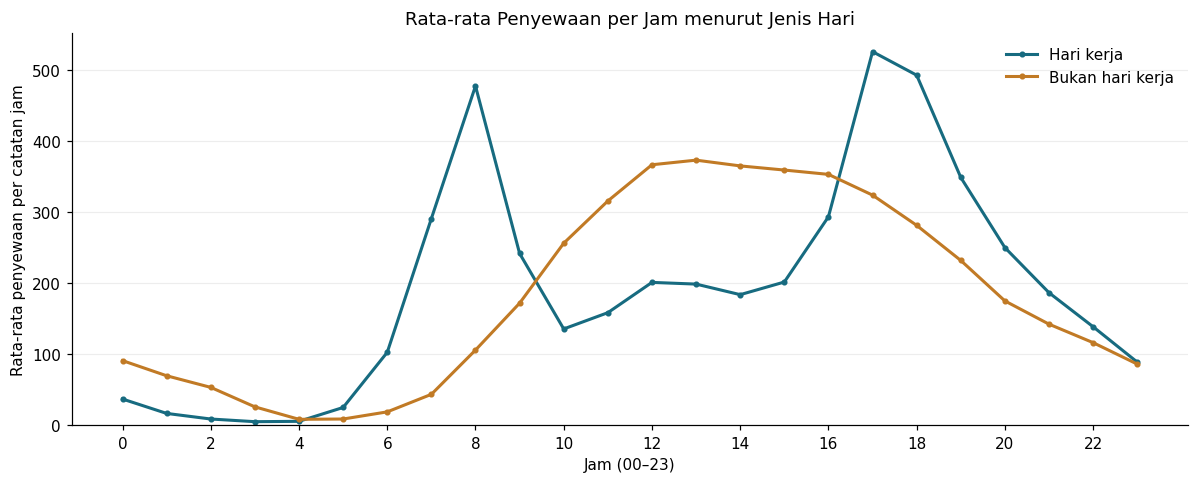

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
warna_hari = {'Hari kerja': '#176B80', 'Bukan hari kerja': '#C17A25'}
for jenis in ['Hari kerja', 'Bukan hari kerja']:
    ax.plot(jam_hari.index, jam_hari[jenis], marker='o', markersize=3,
            linewidth=2, color=warna_hari[jenis], label=jenis)
ax.set_title('Rata-rata Penyewaan per Jam menurut Jenis Hari')
ax.set_xlabel('Jam (00–23)')
ax.set_ylabel('Rata-rata penyewaan per catatan jam')
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.22)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
for jenis in ['Hari kerja', 'Bukan hari kerja']:
    jam_puncak = int(jam_hari[jenis].idxmax())
    nilai_puncak = jam_hari[jenis].max()
    print(f'{jenis}: jam {jam_puncak:02d}.00, '
          f'rata-rata {nilai_puncak:,.1f} sewa per jam pengamatan')

Hari kerja: jam 17.00, rata-rata 525.3 sewa per jam pengamatan
Bukan hari kerja: jam 13.00, rata-rata 372.7 sewa per jam pengamatan


**Jawaban pertanyaan 2:** Pola penyewaan antara hari kerja dan bukan hari kerja berbeda. Pada **hari kerja**, rata-rata tertinggi terjadi pukul **17.00 (525,3 penyewaan per catatan jam)**. Pada **bukan hari kerja**, puncaknya bergeser ke pukul **13.00 (372,7 penyewaan per catatan jam)**.

Hari kerja menunjukkan lonjakan yang jelas pada pagi dan sore hari, sementara bukan hari kerja cenderung ramai dari menjelang siang hingga sore. Pola ini dapat menjadi bahan pertimbangan untuk penempatan sepeda dan jadwal pemeriksaan armada, tetapi belum cukup untuk memastikan alasan perilaku tiap pengguna.

## Analisis Lanjutan — Binning dan Manual Grouping

**Tujuan:** Membagi 24 jam menjadi lima kelompok waktu agar perbedaan pemakaian lebih mudah diringkas tanpa harus membaca 24 titik sekaligus. Teknik yang digunakan adalah **binning dengan `pd.cut()`**, bukan algoritma machine learning.

Aturan kelompok dibuat sendiri: **Dini hari (00–05), Pagi (06–09), Siang (10–15), Sore (16–19), dan Malam (20–23)**. Jumlah jam pada tiap kelompok tidak sama, sehingga saya membandingkan **rata-rata per catatan jam**, bukan jumlah total per kelompok.

In [ ]:
label_waktu = ['Dini hari', 'Pagi', 'Siang', 'Sore', 'Malam']
hour_df['kelompok_jam'] = pd.cut(
    hour_df['hr'],
    bins=[-1, 5, 9, 15, 19, 23],
    labels=label_waktu
)

segmentasi = (hour_df.groupby(['kelompok_jam', 'jenis_hari'], observed=True)['cnt']
              .agg(['count', 'mean'])
              .rename(columns={'count': 'jumlah_catatan_jam',
                               'mean': 'rata_rata_penyewaan'}))

display(segmentasi.round(1))

jumlah_catatan_jam  rata_rata_penyewaan
kelompok_jam jenis_hari                                               
Dini hari    Bukan hari kerja                1364                 43.0
             Hari kerja                      2912                 16.4
Pagi         Bukan hari kerja                 922                 85.0
             Hari kerja                      1984                277.9
Siang        Bukan hari kerja                1386                338.9
             Hari kerja                      2983                179.7
Sore         Bukan hari kerja                 922                297.3
             Hari kerja                      1994                414.8
Malam        Bukan hari kerja                 920                129.7
             Hari kerja                      1992                165.8

### Visualisasi hasil pengelompokan

Grafik berikut membandingkan kelompok waktu pada hari kerja dan bukan hari kerja. Sumbu Y tetap berupa rata-rata penyewaan per jam pengamatan, sehingga kelompok yang berisi lebih banyak jam tidak otomatis mendapat nilai lebih tinggi.

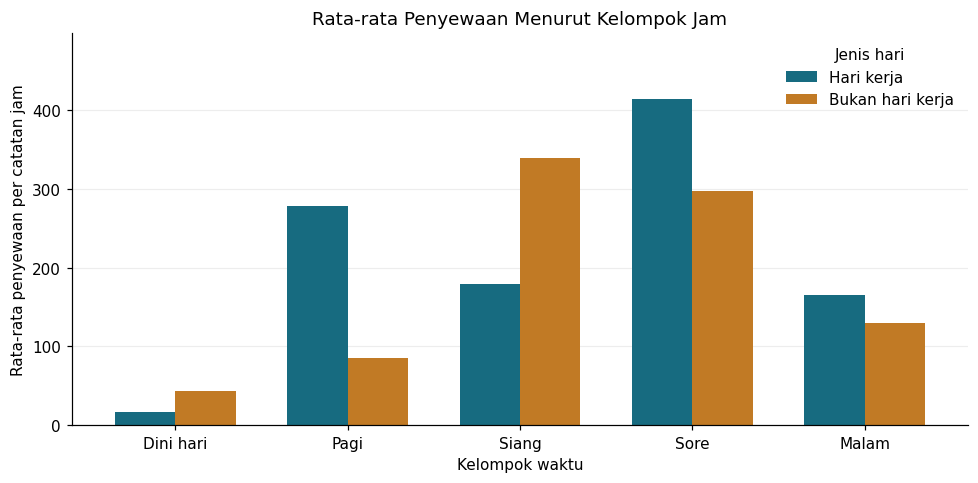

In [ ]:
segment_plot = (hour_df.groupby(['kelompok_jam', 'jenis_hari'], observed=True)['cnt']
                .mean().unstack().reindex(label_waktu))

fig, ax = plt.subplots(figsize=(9, 4.5))
segment_plot[['Hari kerja', 'Bukan hari kerja']].plot(
    kind='bar', ax=ax, color=['#176B80', '#C17A25'], width=0.7)
ax.set_title('Rata-rata Penyewaan Menurut Kelompok Jam')
ax.set_xlabel('Kelompok waktu')
ax.set_ylabel('Rata-rata penyewaan per catatan jam')
ax.set_ylim(0, segment_plot.max().max() * 1.2)
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Jenis hari', frameon=False)
ax.grid(axis='y', alpha=0.22)
ax.set_axisbelow(True)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

### Pemeriksaan tambahan — Kesesuaian total `day.csv` dan `hour.csv`

 `cnt` pada `hour.csv` dijumlahkan berdasarkan tanggal, lalu mencocokkannya dengan `cnt` harian. Pemeriksaan ini penting karena dua dataset digunakan untuk dua pertanyaan yang berbeda.

In [ ]:
total_hour = (hour_df.groupby('dteday', as_index=False)['cnt']
              .sum().rename(columns={'cnt': 'total_dari_hour'}))

cek_total = day_df[['dteday', 'cnt']].merge(
    total_hour, on='dteday', how='left', validate='one_to_one'
)
cek_total['selisih'] = cek_total['cnt'] - cek_total['total_dari_hour']

print('Tanggal tanpa pasangan di hour.csv:', cek_total['total_dari_hour'].isna().sum())
print('Tanggal dengan total yang berbeda:', cek_total['selisih'].fillna(0).ne(0).sum())
display(cek_total.head())

Tanggal tanpa pasangan di hour.csv: 0
Tanggal dengan total yang berbeda: 0


,dteday,cnt,total_dari_hour,selisih
0,2011-01-01,985,985,0
1,2011-01-02,801,801,0
2,2011-01-03,1349,1349,0
3,2011-01-04,1562,1562,0
4,2011-01-05,1600,1600,0


In [ ]:
# Pemeriksaan jumlah baris jam yang tercatat pada tiap tanggal
jumlah_jam_per_hari = hour_df.groupby('dteday').size()

print('Jumlah tanggal dengan kurang dari 24 catatan jam:',
      (jumlah_jam_per_hari < 24).sum())
print('Slot jam yang tidak tercatat:',
      len(day_df) * 24 - len(hour_df))
print('Total penyewaan dari day.csv :', day_df['cnt'].sum())
print('Total penyewaan dari hour.csv:', hour_df['cnt'].sum())

Jumlah tanggal dengan kurang dari 24 catatan jam: 76
Slot jam yang tidak tercatat: 165
Total penyewaan dari day.csv : 3292679
Total penyewaan dari hour.csv: 3292679


**Hasil analisis lanjutan:** Pada **hari kerja**, kelompok **sore (16–19)** mempunyai rata-rata tertinggi, sekitar **414,8 penyewaan per catatan jam**. Pada **bukan hari kerja**, kelompok **siang (10–15)** paling tinggi, sekitar **338,9 penyewaan per catatan jam**.

Hasil pengelompokan mendukung grafik per jam: kebutuhan pada hari kerja lebih terkonsentrasi sekitar waktu pulang kerja, sedangkan pada bukan hari kerja lebih menonjol di siang hari. Ini merupakan pengelompokan deskriptif, bukan klasifikasi pelanggan.

Penjumlahan `hour.csv` untuk setiap tanggal **sama persis** dengan total `day.csv` pada tanggal yang sama. Sebanyak **76 hari** memiliki kurang dari 24 baris jam. Slot yang tidak muncul tidak saya isi secara otomatis; karena itu rata-rata per jam merujuk pada pengamatan yang tercatat.

In [ ]:
for jenis in ['Hari kerja', 'Bukan hari kerja']:
    kolom = segment_plot[jenis]
    print(f'Kelompok jam paling ramai ({jenis.lower()}): {kolom.idxmax()} '
          f'— {kolom.max():,.1f} sewa/jam pengamatan')

Kelompok jam paling ramai (hari kerja): Sore — 414.8 sewa/jam pengamatan
Kelompok jam paling ramai (bukan hari kerja): Siang — 338.9 sewa/jam pengamatan


## Conclusion & Recommendation

Bagian ini menjawab dua pertanyaan bisnis sesuai hasil yang ditemukan. Kesimpulan dibatasi pada pola yang terlihat dalam data 2011–2012. Angka di bawah merupakan hasil dari CSV asli yang digunakan pada notebook ini.

In [ ]:
print('PERTANYAAN 1')
print(f'Bulan tertinggi : {bulanan.idxmax()} ({bulanan.max():,.1f} sewa/hari)')
print(f'Musim tertinggi : {musiman.idxmax()} ({musiman.max():,.1f} sewa/hari)')

print('\nPERTANYAAN 2')
for jenis in ['Hari kerja', 'Bukan hari kerja']:
    jam = int(jam_hari[jenis].idxmax())
    print(f'{jenis}: pukul {jam:02d}.00 ({jam_hari[jenis].max():,.1f} sewa/jam)')

print('\nANALISIS LANJUTAN')
print('Jumlah tanggal dengan selisih total:', cek_total['selisih'].fillna(0).ne(0).sum())

PERTANYAAN 1
Bulan tertinggi : 2012-09 (7,285.8 sewa/hari)
Musim tertinggi : Gugur (5,644.3 sewa/hari)

PERTANYAAN 2
Hari kerja: pukul 17.00 (525.3 sewa/jam)
Bukan hari kerja: pukul 13.00 (372.7 sewa/jam)

ANALISIS LANJUTAN
Jumlah tanggal dengan selisih total: 0


### Kesimpulan

**Pertanyaan 1 — Bulan dan musim:** Rata-rata penyewaan harian paling tinggi terjadi pada **September 2012**, sekitar **7.285,8 penyewaan/hari**. Jika dikelompokkan menurut musim selama 2011–2012, **musim gugur** memiliki rata-rata tertinggi, **5.644,3 penyewaan/hari**, sedangkan **musim semi** terendah, **2.604,1 penyewaan/hari**. Jumlah penyewaan tidak merata sepanjang tahun.

**Pertanyaan 2 — Jam dan jenis hari:** Pada **hari kerja**, puncak rata-rata penyewaan terjadi pukul **17.00 (525,3 per catatan jam)**. Pada **bukan hari kerja**, puncaknya terjadi pukul **13.00 (372,7 per catatan jam)**. Jadi, waktu ramai berubah menurut jenis harinya.

**Hasil pengelompokan jam:** Dengan binning, kelompok paling ramai pada hari kerja adalah **sore (16–19), rata-rata 414,8**, sedangkan pada bukan hari kerja adalah **siang (10–15), rata-rata 338,9** penyewaan per catatan jam. Teknik ini membantu merangkum pola tanpa model machine learning.

### Rekomendasi

- **Pengelolaan armada:** Pertimbangkan kesiapan sepeda yang lebih besar menjelang sore pada hari kerja dan menjelang siang pada bukan hari kerja. Ini merupakan usulan dari pola historis, bukan bukti bahwa penambahan sepeda pasti menaikkan penyewaan.
- **Perencanaan musiman:** Gunakan temuan tentang bulan dan musim ramai sebagai bahan awal untuk menyusun jadwal inspeksi dan ketersediaan sepeda. Perlu data tahun yang lebih baru sebelum menerapkannya untuk kondisi sekarang.
- **Analisis berikutnya:** Jika tersedia data lokasi stasiun dan identitas transaksi, analisis dapat diperluas ke pemerataan sepeda antarstasiun. Dataset saat ini belum memuat informasi tersebut.

**Batasan:** Hasil ini bersifat deskriptif, hanya mencakup 2011–2012, dan tidak menyatakan hubungan sebab-akibat. Ada jam yang tidak tercatat pada beberapa hari; rata-rata per jam dihitung dari baris yang ada. `cnt` menghitung penyewaan, bukan orang unik.